> **اجرا در Google Colab:** ابتدا سلول زیر را اجرا کنید تا کتابخانه‌ها نصب شوند (در Colab فقط `torch_geometric` لازم است).

In [1]:
!pip install -q torch_geometric networkx scikit-learn matplotlib

# تمرین ۵ — طبقه‌بندی موضوعی مقالات شبکه استنادی Cora با GCN و مقایسه با MLP

مراحل:
1. بارگذاری داده Cora و آمار آن
2. رسم زیرگراف مقالات با networkx (رنگ = موضوع)
3. مدل MLP (فقط بردار کلمات، بدون گراف)
4. مدل GCN دو لایه (بردار کلمات + گراف ارجاعات)
5. آموزش هر دو مدل و رسم منحنی Loss / Accuracy
6. ارزیابی نهایی روی داده تست + ماتریس درهم‌ریختگی + t-SNE + تکرار با چند seed

## بخش ۰: کتابخانه‌ها و تنظیمات

In [2]:
# بخش ۰: کتابخانه‌ها و تنظیمات
import os
import json
import random
import warnings

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import networkx as nx
import matplotlib

import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from torch_geometric.datasets import Planetoid
import torch_geometric.transforms as T

warnings.filterwarnings("ignore")

OUT_DIR = "outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# ابرپارامترها (همان مقادیر مقاله اصلی GCN: Kipf & Welling 2017)
HIDDEN = 16          # تعداد نورون لایه پنهان
DROPOUT = 0.5        # احتمال dropout
LR = 0.01            # نرخ یادگیری
WEIGHT_DECAY = 5e-4  # منظم‌سازی L2
EPOCHS = 200         # تعداد ایپاک
SEED = 42

# نام هفت موضوع Cora (ترتیب برچسب‌ها در نسخه Planetoid)
CLASS_NAMES = [
    "Theory",
    "Reinforcement_Learning",
    "Genetic_Algorithms",
    "Neural_Networks",
    "Probabilistic_Methods",
    "Case_Based",
    "Rule_Learning",
]


def set_seed(seed: int) -> None:
    """ثابت کردن تصادفی‌بودن برای تکرارپذیری نتایج."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/usr/local/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


device: cpu


## بخش ۱: بارگذاری داده Cora

In [3]:
# بخش ۱: بارگذاری داده Cora
# NormalizeFeatures: هر بردار کلمات را طوری تقسیم می‌کند که جمع درایه‌هایش 1 شود (مثل مقاله اصلی GCN)
dataset = Planetoid(root="data", name="Cora", transform=T.NormalizeFeatures())  # اولین اجرا خودکار دانلود می‌شود
data = dataset[0].to(device)

num_nodes = data.num_nodes
num_features = dataset.num_features
num_classes = dataset.num_classes

print("=" * 60)
print(f"تعداد گره‌ها (مقالات)       : {num_nodes}")
print(f"تعداد یال‌ها (ارجاع، دوطرفه) : {data.num_edges // 2}")
print(f"طول بردار ویژگی (کلمات)     : {num_features}")
print(f"تعداد کلاس‌ها (موضوعات)      : {num_classes}")
print(f"گره‌های آموزش / اعتبارسنجی / تست: "
      f"{int(data.train_mask.sum())} / {int(data.val_mask.sum())} / {int(data.test_mask.sum())}")
print(f"میانگین درجه گره‌ها          : {data.num_edges / num_nodes:.2f}")
print("=" * 60)

# توزیع کلاس‌ها
class_counts = torch.bincount(data.y, minlength=num_classes).cpu().numpy()
for c, n in enumerate(class_counts):
    print(f"  کلاس {c} ({CLASS_NAMES[c]:<24}): {n}")

# همگونی (homophily): درصد یال‌هایی که دو سرشان هم‌موضوع‌اند
src, dst = data.edge_index
homophily = (data.y[src] == data.y[dst]).float().mean().item()
print(f"نسبت یال‌های هم‌موضوع (homophily): {homophily:.3f}")

تعداد گره‌ها (مقالات)       : 2708
تعداد یال‌ها (ارجاع، دوطرفه) : 5278
طول بردار ویژگی (کلمات)     : 1433
تعداد کلاس‌ها (موضوعات)      : 7
گره‌های آموزش / اعتبارسنجی / تست: 140 / 500 / 1000
میانگین درجه گره‌ها          : 3.90
  کلاس 0 (Theory                  ): 351
  کلاس 1 (Reinforcement_Learning  ): 217
  کلاس 2 (Genetic_Algorithms      ): 418
  کلاس 3 (Neural_Networks         ): 818
  کلاس 4 (Probabilistic_Methods   ): 426
  کلاس 5 (Case_Based              ): 298
  کلاس 6 (Rule_Learning           ): 180
نسبت یال‌های هم‌موضوع (homophily): 0.810


## بخش ۲: رسم زیرگراف مقالات با networkx (رنگ هر گره = موضوع مقاله)

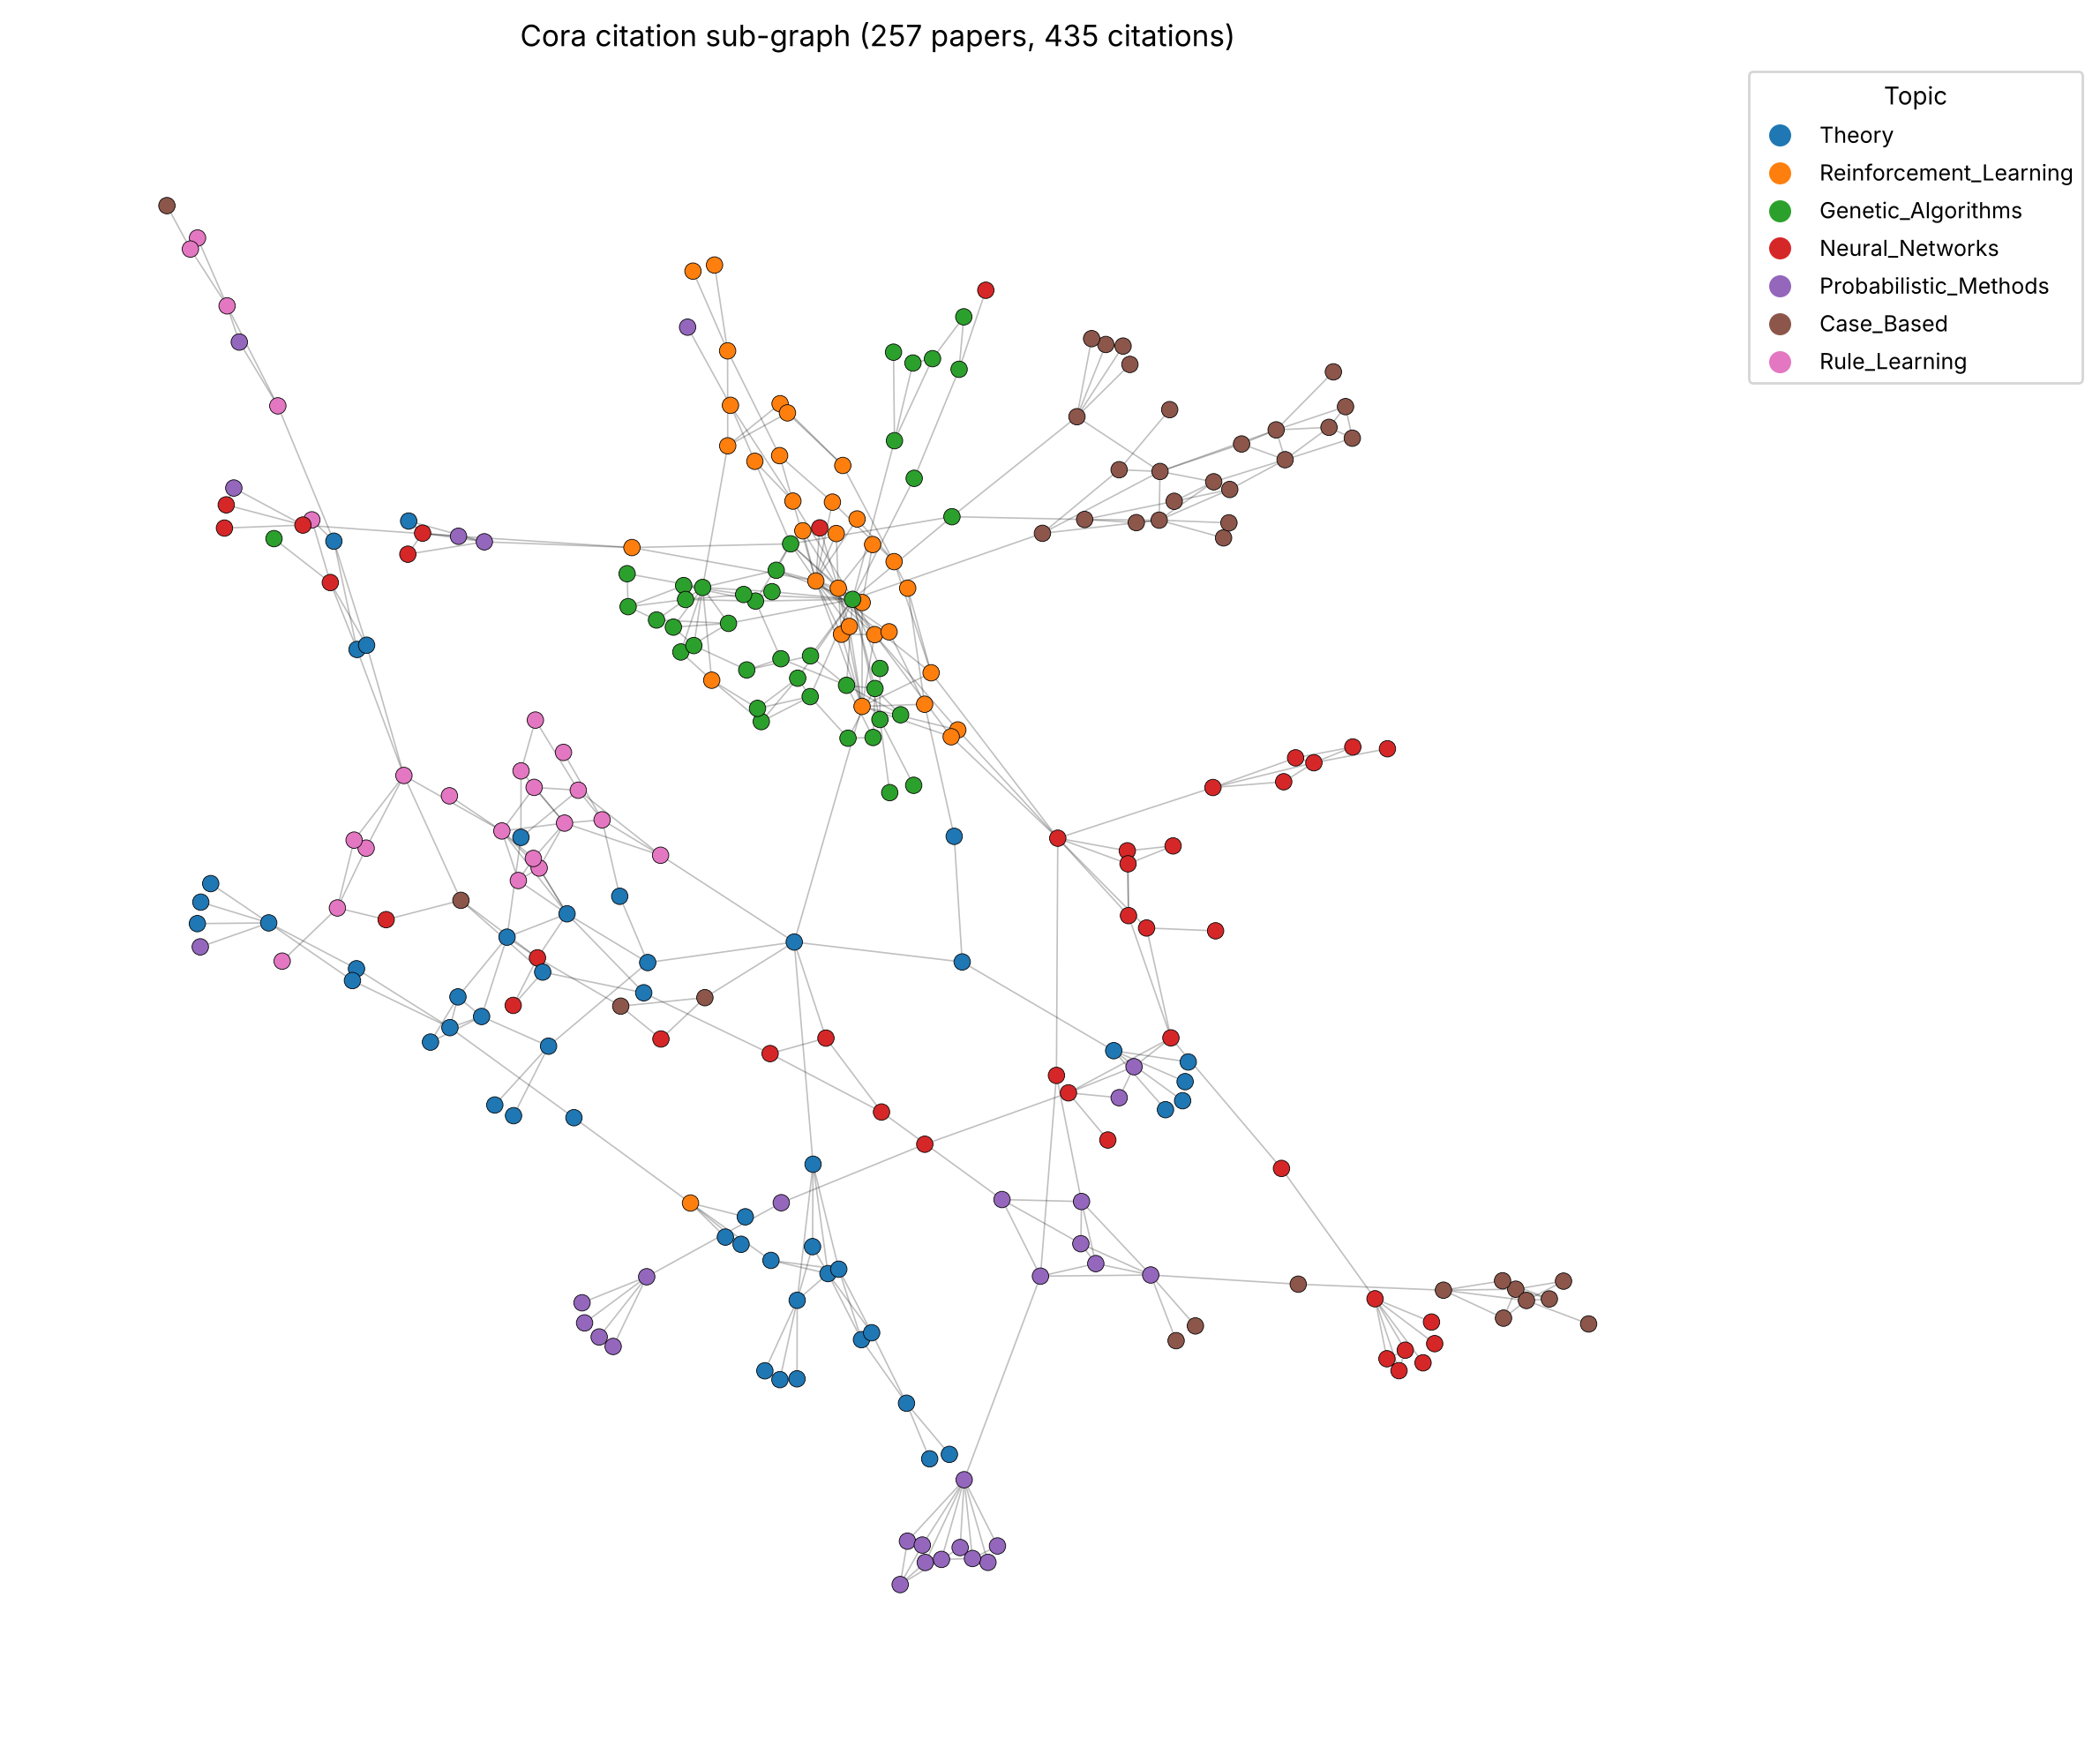

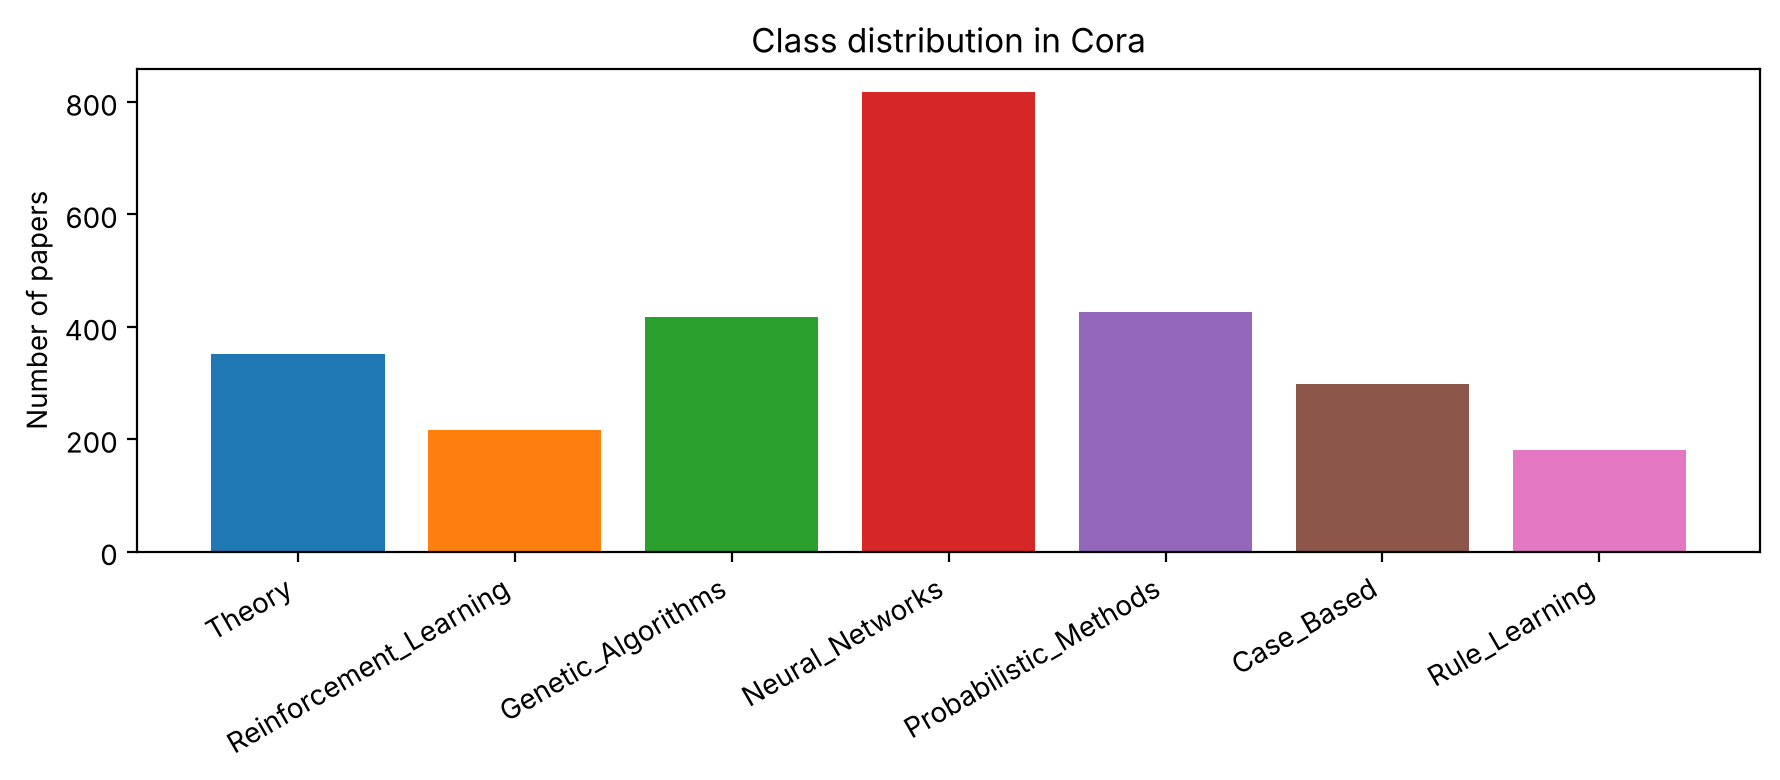

In [4]:
# بخش ۲: رسم زیرگراف مقالات با networkx (رنگ هر گره = موضوع مقاله)
G_full = nx.Graph()
G_full.add_nodes_from(range(num_nodes))
G_full.add_edges_from(data.edge_index.t().cpu().numpy().tolist())

# انتخاب زیرشبکه: از هر موضوع 8 مقاله تصادفی (گره بذر) برمی‌داریم و همسایه‌های مستقیمشان را اضافه می‌کنیم
# تا همه موضوعات در شکل حضور داشته باشند؛ سپس بزرگ‌ترین مؤلفه همبند را رسم می‌کنیم.
labels_np = data.y.cpu().numpy()
rng = np.random.default_rng(SEED)
seeds = []
for c in range(num_classes):
    cand = [n for n in np.where(labels_np == c)[0] if 3 <= G_full.degree(n) <= 15]
    seeds += rng.choice(cand, size=8, replace=False).tolist()
sub_nodes = set(seeds)
for n in seeds:
    sub_nodes.update(G_full.neighbors(n))
G_tmp = G_full.subgraph(sub_nodes)
G_sub = G_tmp.subgraph(max(nx.connected_components(G_tmp), key=len)).copy()
if G_sub.number_of_nodes() < 150:   # اگر مؤلفه بزرگ کوچک بود، کل زیرگراف را نشان بده
    G_sub = G_tmp.copy()

cmap = plt.get_cmap("tab10")
node_colors = [cmap(labels_np[n]) for n in G_sub.nodes()]

plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G_sub, seed=SEED)
nx.draw_networkx_edges(G_sub, pos, alpha=0.25, width=0.6)
nx.draw_networkx_nodes(G_sub, pos, node_color=node_colors, node_size=45,
                       edgecolors="black", linewidths=0.3)
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=cmap(i),
                      markersize=10, label=CLASS_NAMES[i]) for i in range(num_classes)]
plt.legend(handles=handles, title="Topic", loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9)
plt.title(f"Cora citation sub-graph ({G_sub.number_of_nodes()} papers, "
          f"{G_sub.number_of_edges()} citations)")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "01_cora_subgraph.png"), dpi=150)
plt.show()

# نمودار توزیع کلاس‌ها
plt.figure(figsize=(9, 4))
plt.bar(CLASS_NAMES, class_counts, color=[cmap(i) for i in range(num_classes)])
plt.xticks(rotation=30, ha="right")
plt.ylabel("Number of papers")
plt.title("Class distribution in Cora")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "02_class_distribution.png"), dpi=150)
plt.show()

## بخش ۳: ساخت ماتریس مجاورت نرمال‌شده  Â = D^(-1/2) (A + I) D^(-1/2)

In [5]:
# بخش ۳: ساخت ماتریس مجاورت نرمال‌شده  Â = D^(-1/2) (A + I) D^(-1/2)
def normalized_adjacency(edge_index: torch.Tensor, n: int) -> torch.Tensor:
    """
    ورودی: لیست یال‌ها (2 × E)
    خروجی: ماتریس اسپارس Â که در فرمول GCN استفاده می‌شود.
      1) A + I : هر گره به خودش هم وصل می‌شود (ویژگی خودش حفظ شود)
      2) D     : درجه هر گره در A + I
      3) نرمال‌سازی متقارن تا مقادیر برای گره‌های پرارجاع منفجر نشود
    """
    self_loops = torch.arange(n, device=edge_index.device)
    row = torch.cat([edge_index[0], self_loops])
    col = torch.cat([edge_index[1], self_loops])
    values = torch.ones(row.size(0), device=edge_index.device)

    deg = torch.zeros(n, device=edge_index.device).scatter_add_(0, row, values)
    deg_inv_sqrt = deg.pow(-0.5)
    norm_values = deg_inv_sqrt[row] * values * deg_inv_sqrt[col]

    return torch.sparse_coo_tensor(torch.stack([row, col]), norm_values, (n, n)).coalesce()


A_hat = normalized_adjacency(data.edge_index, num_nodes)

## بخش ۴: تعریف مدل‌ها

In [6]:
# بخش ۴: تعریف مدل‌ها

class MLP(nn.Module):
    """
    مدل پایه (baseline) غیرگرافی: هر مقاله مستقل از بقیه و فقط با بردار کلماتش طبقه‌بندی می‌شود.
    معماری: 1433 → Linear → ReLU → Dropout → Linear → 7
    """

    def __init__(self, in_dim, hidden_dim, out_dim, dropout):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x, adj=None, return_hidden=False):  # adj استفاده نمی‌شود!
        x = F.dropout(x, p=self.dropout, training=self.training)
        h = F.relu(self.fc1(x))
        h = F.dropout(h, p=self.dropout, training=self.training)
        out = self.fc2(h)
        return (out, h) if return_hidden else out


class GCNLayer(nn.Module):
    """
    یک لایه کانولوشن گرافی:   H' = Â · H · W
      H · W  : تبدیل خطی ویژگی‌های هر گره (مثل یک لایه Linear)
      Â · …  : هر گره میانگین وزن‌دار ویژگی‌های خودش و همسایگانش را می‌گیرد (message passing)
    """

    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.linear = nn.Linear(in_dim, out_dim, bias=False)
        self.bias = nn.Parameter(torch.zeros(out_dim))
        nn.init.xavier_uniform_(self.linear.weight)

    def forward(self, x, adj):
        support = self.linear(x)                 # H · W
        out = torch.sparse.mm(adj, support)      # Â · (H · W)
        return out + self.bias


class GCN(nn.Module):
    """
    GCN استاندارد دو لایه (Kipf & Welling):
      Z = softmax( Â · ReLU( Â · X · W1 ) · W2 )
    لایه ورودی: بردار کلمات 1433 بعدی — خروجی: 7 کلاس موضوعی
    """

    def __init__(self, in_dim, hidden_dim, out_dim, dropout):
        super().__init__()
        self.gc1 = GCNLayer(in_dim, hidden_dim)
        self.gc2 = GCNLayer(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x, adj, return_hidden=False):
        x = F.dropout(x, p=self.dropout, training=self.training)
        h = F.relu(self.gc1(x, adj))
        h = F.dropout(h, p=self.dropout, training=self.training)
        out = self.gc2(h, adj)                   # logits؛ softmax داخل cross_entropy است
        return (out, h) if return_hidden else out


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## بخش ۵: حلقه آموزش و ارزیابی (مشترک برای هر دو مدل)

In [7]:
# بخش ۵: حلقه آموزش و ارزیابی (مشترک برای هر دو مدل)

def accuracy(logits, y, mask):
    pred = logits[mask].argmax(dim=1)
    return (pred == y[mask]).float().mean().item()


def train_model(model, epochs=EPOCHS, verbose=True):
    """
    آموزش نیمه‌نظارتی (semi-supervised):
      Loss فقط روی 140 گره آموزشی محاسبه می‌شود، اما در GCN همه گره‌ها (با گراف) در محاسبه شرکت دارند.
    بهترین مدل بر اساس دقت اعتبارسنجی ذخیره می‌شود.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    history = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "test_acc"]}
    best_val, best_state = -1, None

    for epoch in range(1, epochs + 1):
        # ---- آموزش ----
        model.train()
        optimizer.zero_grad()
        out = model(data.x, A_hat)
        loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()

        # ---- ارزیابی ----
        model.eval()
        with torch.no_grad():
            out = model(data.x, A_hat)
            val_loss = F.cross_entropy(out[data.val_mask], data.y[data.val_mask]).item()
            tr_acc = accuracy(out, data.y, data.train_mask)
            va_acc = accuracy(out, data.y, data.val_mask)
            te_acc = accuracy(out, data.y, data.test_mask)

        history["train_loss"].append(loss.item())
        history["val_loss"].append(val_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)
        history["test_acc"].append(te_acc)

        if va_acc > best_val:
            best_val = va_acc
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        if verbose and (epoch == 1 or epoch % 20 == 0):
            print(f"epoch {epoch:3d} | train loss {loss.item():.4f} | val loss {val_loss:.4f} | "
                  f"train acc {tr_acc:.3f} | val acc {va_acc:.3f} | test acc {te_acc:.3f}")

    model.load_state_dict(best_state)
    return history


@torch.no_grad()
def evaluate(model):
    model.eval()
    out, hidden = model(data.x, A_hat, return_hidden=True)
    pred = out.argmax(dim=1)
    m = data.test_mask
    return {
        "test_acc": (pred[m] == data.y[m]).float().mean().item(),
        "test_macro_f1": f1_score(data.y[m].cpu(), pred[m].cpu(), average="macro"),
        "pred": pred.cpu().numpy(),
        "hidden": hidden.cpu().numpy(),
    }

## بخش ۶: آموزش MLP

In [8]:
# بخش ۶: آموزش MLP
print("\n########## MLP (only bag-of-words, no graph) ##########")
set_seed(SEED)
mlp = MLP(num_features, HIDDEN, num_classes, DROPOUT).to(device)
print(mlp)
print("trainable parameters:", count_params(mlp))
hist_mlp = train_model(mlp)
res_mlp = evaluate(mlp)
print(f"MLP  -> test accuracy = {res_mlp['test_acc']:.4f} | macro-F1 = {res_mlp['test_macro_f1']:.4f}")


########## MLP (only bag-of-words, no graph) ##########
MLP(
  (fc1): Linear(in_features=1433, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=7, bias=True)
)
trainable parameters: 23063
epoch   1 | train loss 1.9516 | val loss 1.9718 | train acc 0.143 | val acc 0.072 | test acc 0.091


epoch  20 | train loss 1.8597 | val loss 1.9096 | train acc 1.000 | val acc 0.490 | test acc 0.520


epoch  40 | train loss 1.5283 | val loss 1.8235 | train acc 1.000 | val acc 0.518 | test acc 0.521


epoch  60 | train loss 1.2455 | val loss 1.6950 | train acc 1.000 | val acc 0.540 | test acc 0.537


epoch  80 | train loss 0.8406 | val loss 1.6078 | train acc 1.000 | val acc 0.532 | test acc 0.528


epoch 100 | train loss 0.8538 | val loss 1.5193 | train acc 1.000 | val acc 0.560 | test acc 0.549


epoch 120 | train loss 0.7531 | val loss 1.4754 | train acc 1.000 | val acc 0.570 | test acc 0.548


epoch 140 | train loss 0.7501 | val loss 1.4777 | train acc 1.000 | val acc 0.554 | test acc 0.533


epoch 160 | train loss 0.6559 | val loss 1.4543 | train acc 1.000 | val acc 0.570 | test acc 0.557


epoch 180 | train loss 0.5655 | val loss 1.4264 | train acc 1.000 | val acc 0.578 | test acc 0.560


epoch 200 | train loss 0.6386 | val loss 1.4307 | train acc 1.000 | val acc 0.570 | test acc 0.553
MLP  -> test accuracy = 0.5660 | macro-F1 = 0.5557


## بخش ۷: آموزش GCN

In [9]:
# بخش ۷: آموزش GCN
print("\n########## GCN (bag-of-words + citation graph) ##########")
set_seed(SEED)
gcn = GCN(num_features, HIDDEN, num_classes, DROPOUT).to(device)
print(gcn)
print("trainable parameters:", count_params(gcn))
hist_gcn = train_model(gcn)
res_gcn = evaluate(gcn)
print(f"GCN  -> test accuracy = {res_gcn['test_acc']:.4f} | macro-F1 = {res_gcn['test_macro_f1']:.4f}")


########## GCN (bag-of-words + citation graph) ##########
GCN(
  (gc1): GCNLayer(
    (linear): Linear(in_features=1433, out_features=16, bias=False)
  )
  (gc2): GCNLayer(
    (linear): Linear(in_features=16, out_features=7, bias=False)
  )
)
trainable parameters: 23063
epoch   1 | train loss 1.9452 | val loss 1.9455 | train acc 0.264 | val acc 0.096 | test acc 0.106


epoch  20 | train loss 1.7343 | val loss 1.8231 | train acc 0.807 | val acc 0.482 | test acc 0.489


epoch  40 | train loss 1.3828 | val loss 1.6154 | train acc 0.914 | val acc 0.676 | test acc 0.686


epoch  60 | train loss 1.0599 | val loss 1.3606 | train acc 0.964 | val acc 0.760 | test acc 0.772


epoch  80 | train loss 0.7872 | val loss 1.1668 | train acc 0.979 | val acc 0.786 | test acc 0.794


epoch 100 | train loss 0.6160 | val loss 1.0570 | train acc 0.979 | val acc 0.782 | test acc 0.799


epoch 120 | train loss 0.5280 | val loss 0.9695 | train acc 0.986 | val acc 0.778 | test acc 0.809


epoch 140 | train loss 0.4978 | val loss 0.9234 | train acc 0.993 | val acc 0.780 | test acc 0.803


epoch 160 | train loss 0.4137 | val loss 0.9010 | train acc 1.000 | val acc 0.780 | test acc 0.803


epoch 180 | train loss 0.4410 | val loss 0.8691 | train acc 0.993 | val acc 0.772 | test acc 0.804


epoch 200 | train loss 0.3927 | val loss 0.8311 | train acc 0.993 | val acc 0.788 | test acc 0.812
GCN  -> test accuracy = 0.8150 | macro-F1 = 0.8029


## بخش ۸: رسم منحنی‌های Loss و Accuracy برای هر دو مدل

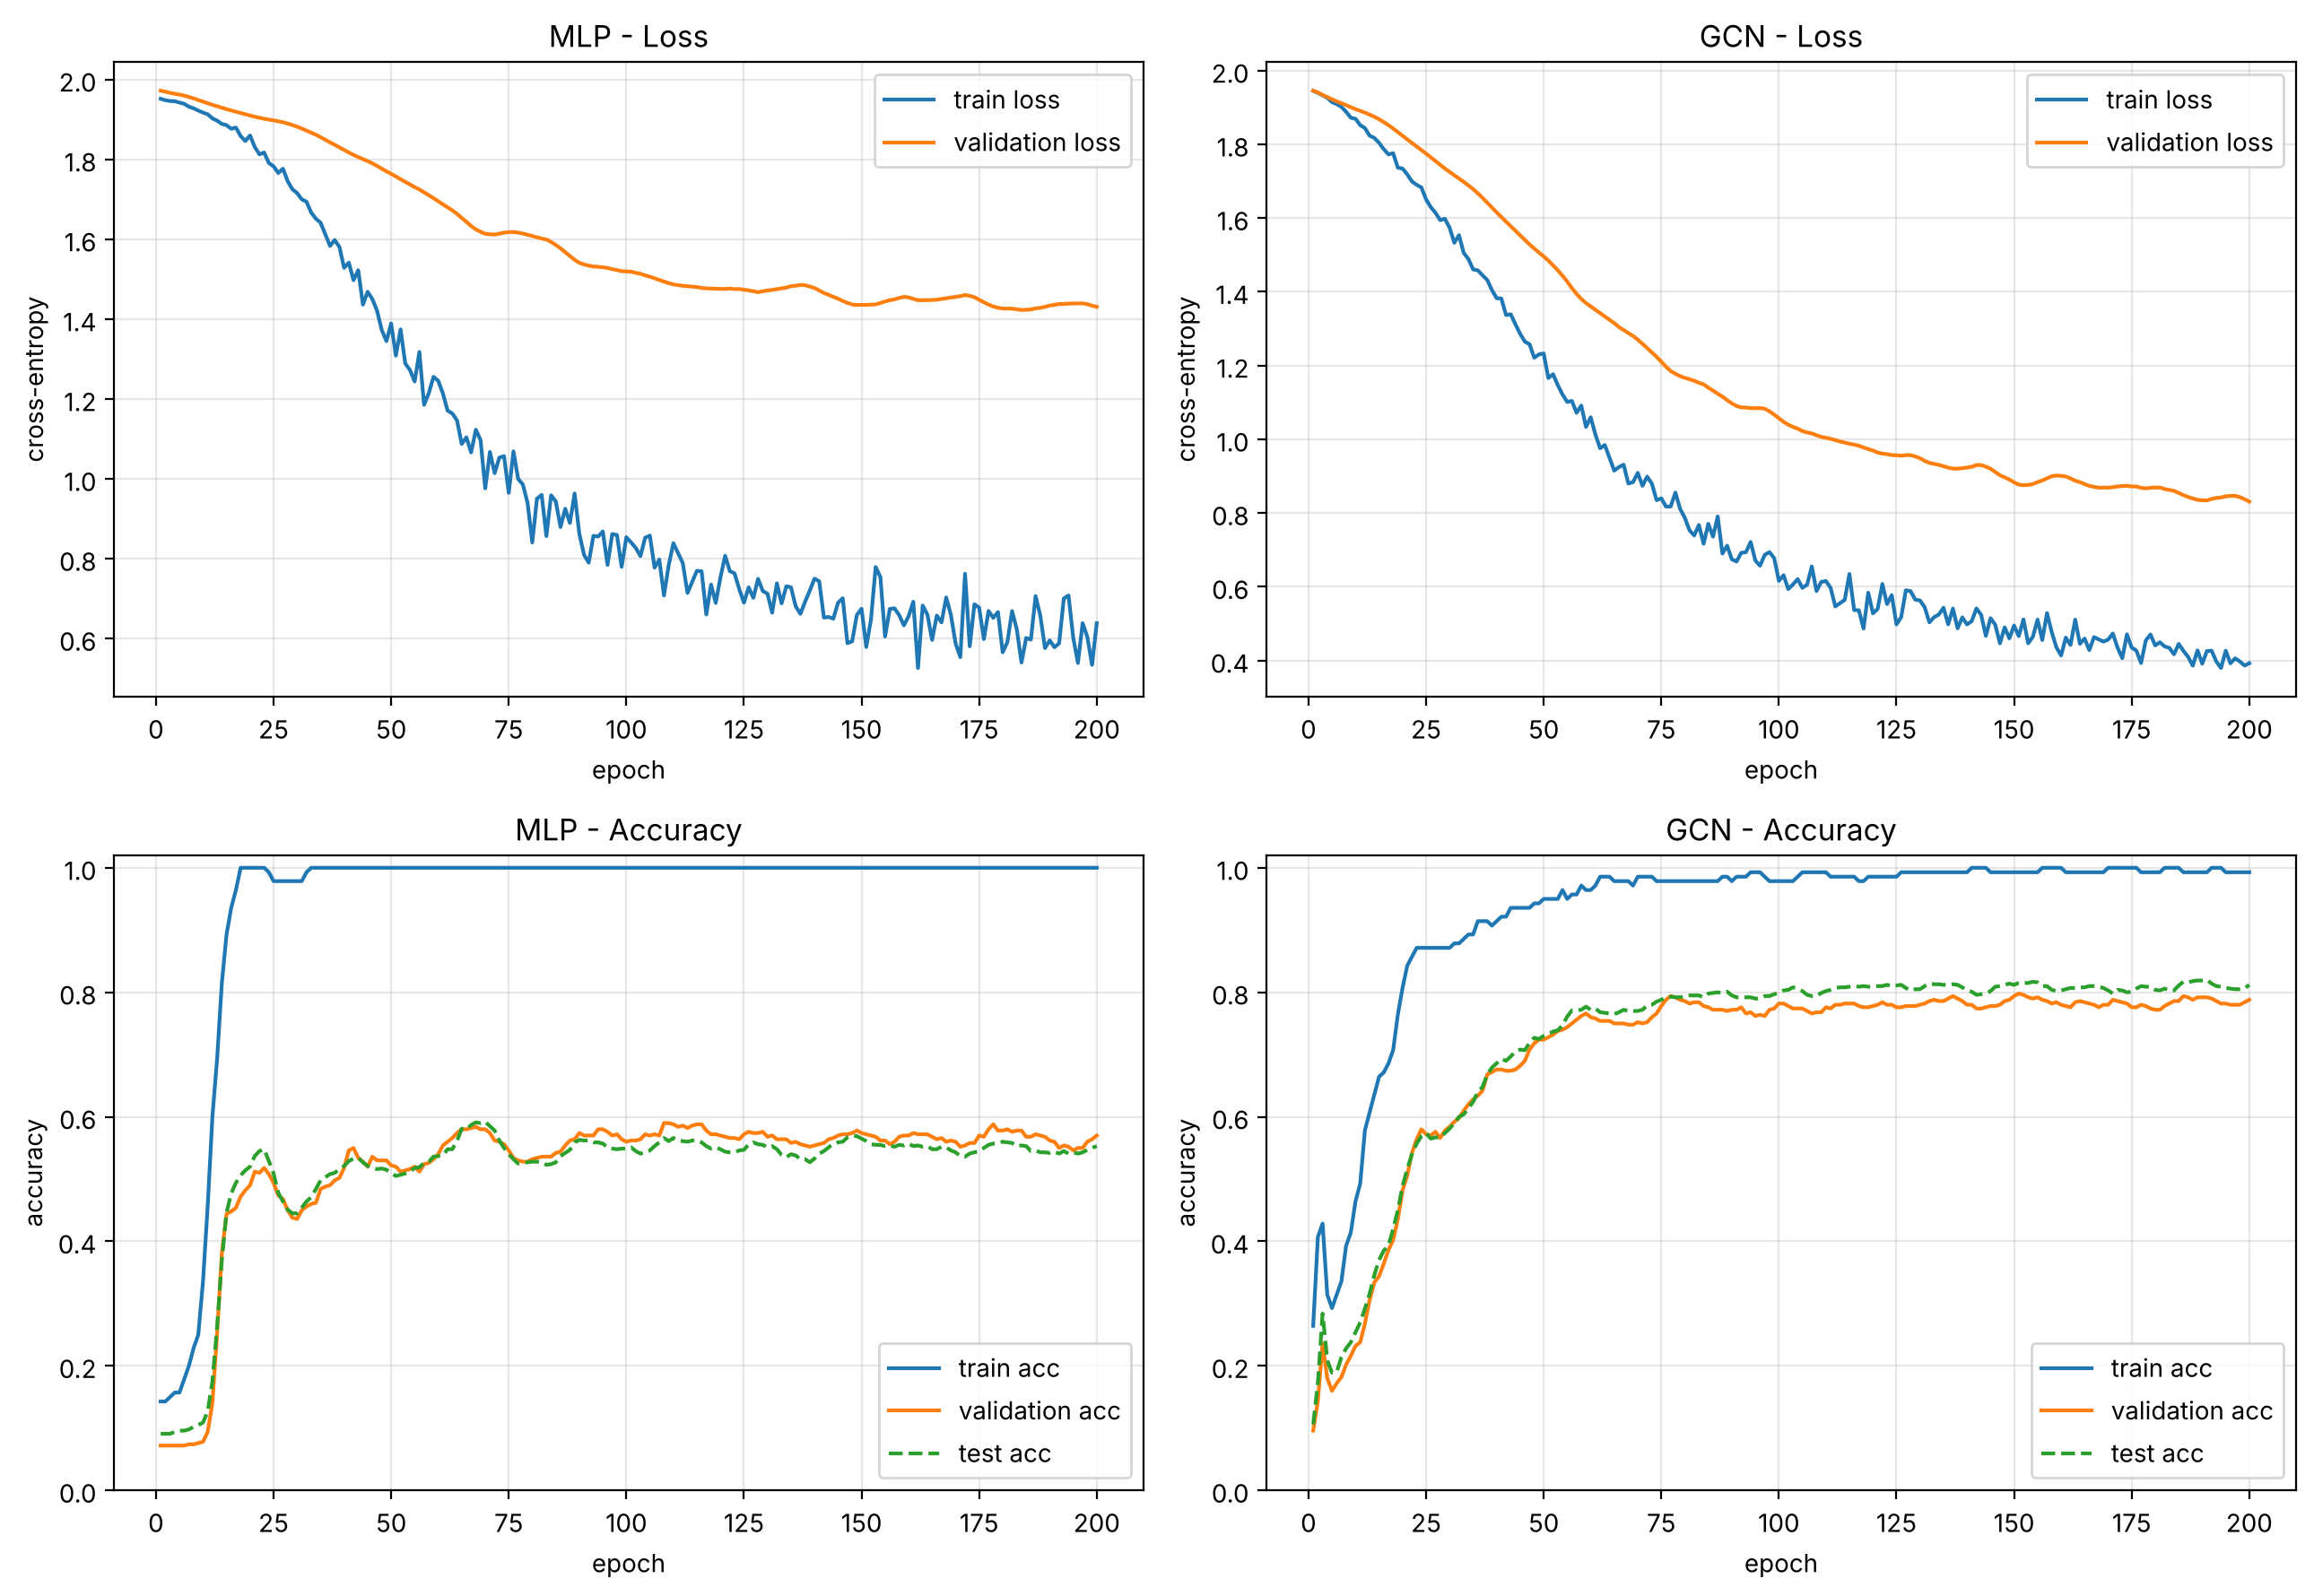

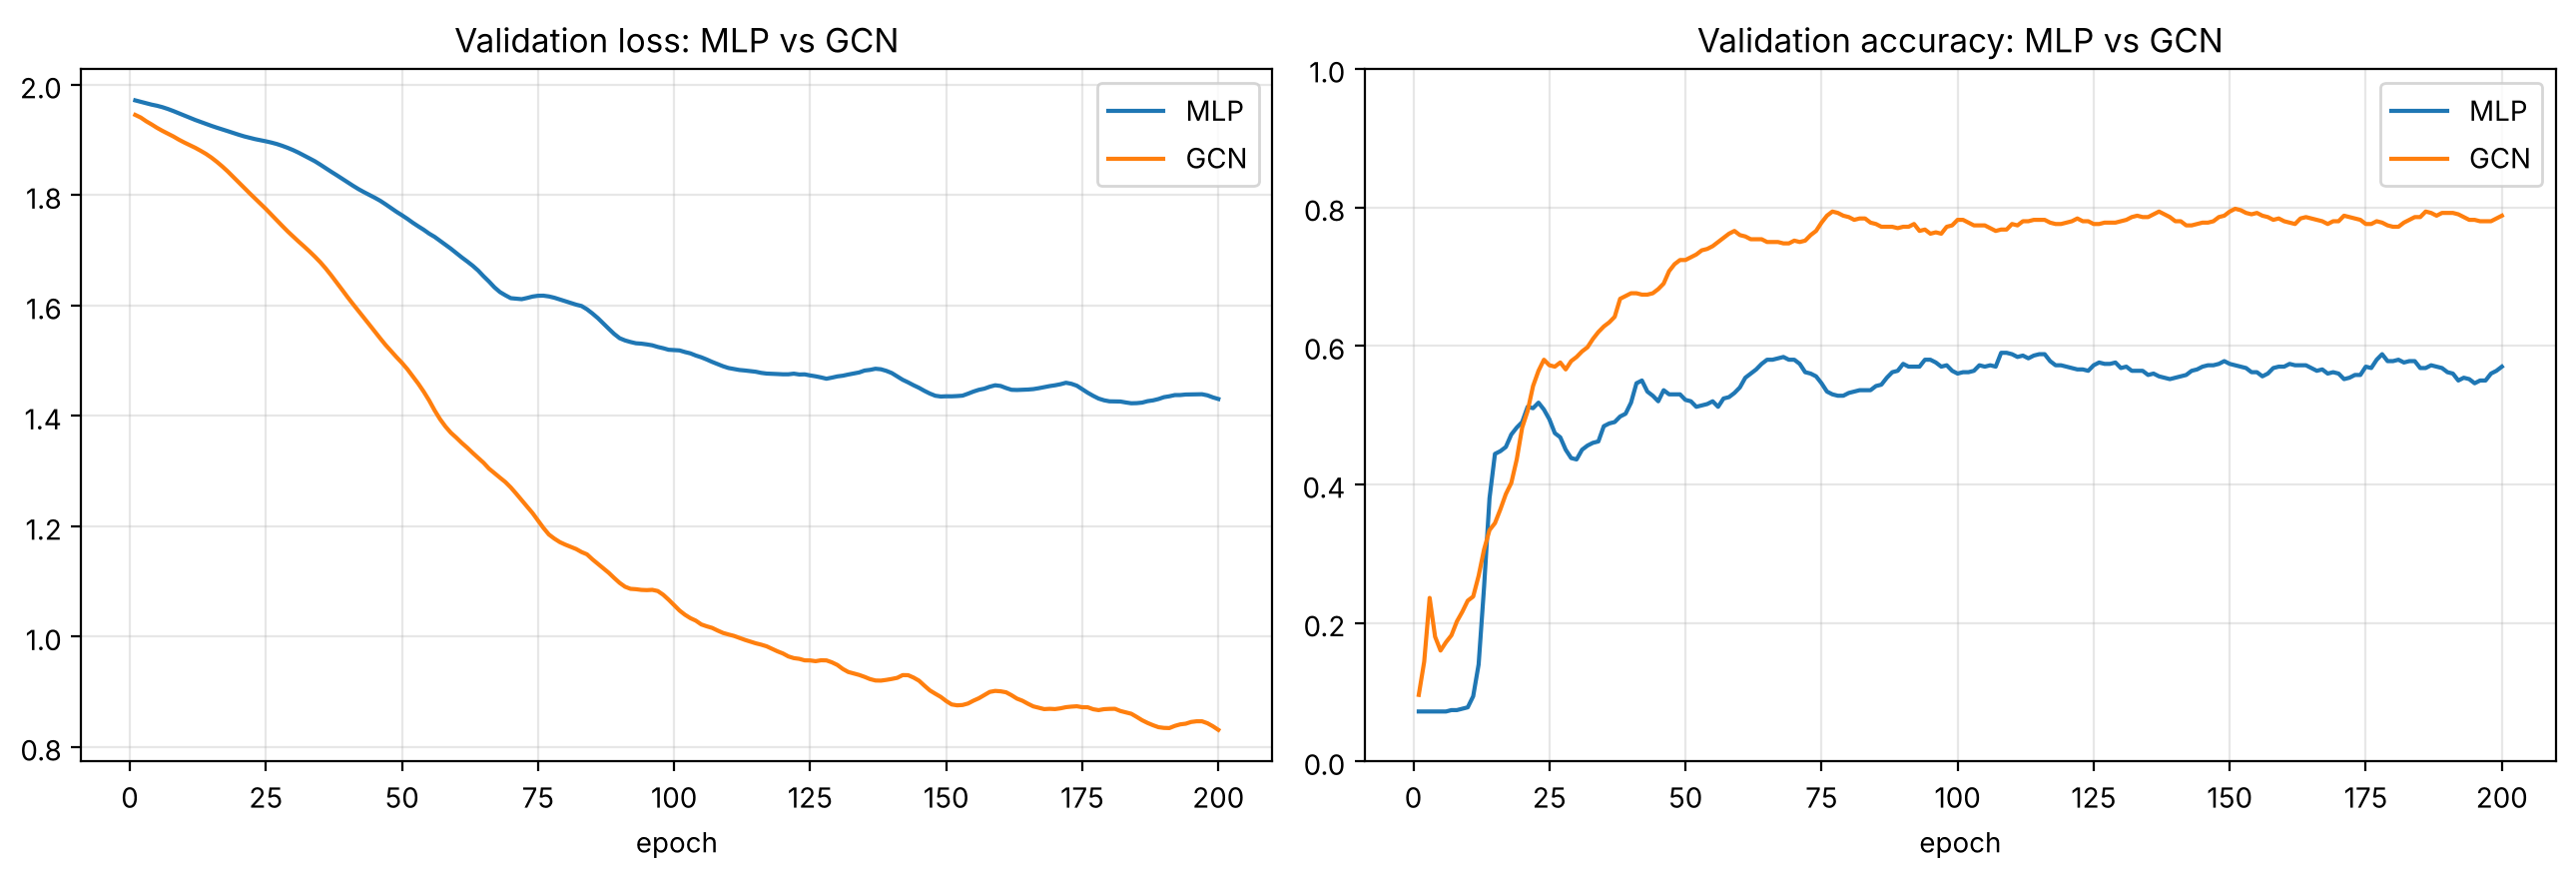

In [10]:
# بخش ۸: رسم منحنی‌های Loss و Accuracy برای هر دو مدل
ep = np.arange(1, EPOCHS + 1)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for col, (name, h) in enumerate([("MLP", hist_mlp), ("GCN", hist_gcn)]):
    ax = axes[0, col]
    ax.plot(ep, h["train_loss"], label="train loss")
    ax.plot(ep, h["val_loss"], label="validation loss")
    ax.set_title(f"{name} - Loss"); ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy")
    ax.grid(alpha=0.3); ax.legend()

    ax = axes[1, col]
    ax.plot(ep, h["train_acc"], label="train acc")
    ax.plot(ep, h["val_acc"], label="validation acc")
    ax.plot(ep, h["test_acc"], label="test acc", linestyle="--")
    ax.set_title(f"{name} - Accuracy"); ax.set_xlabel("epoch"); ax.set_ylabel("accuracy")
    ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "03_loss_accuracy_curves.png"), dpi=150)
plt.show()

# مقایسه مستقیم دو مدل روی یک نمودار
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ep, hist_mlp["val_loss"], label="MLP"); axes[0].plot(ep, hist_gcn["val_loss"], label="GCN")
axes[0].set_title("Validation loss: MLP vs GCN"); axes[0].set_xlabel("epoch"); axes[0].grid(alpha=0.3); axes[0].legend()
axes[1].plot(ep, hist_mlp["val_acc"], label="MLP"); axes[1].plot(ep, hist_gcn["val_acc"], label="GCN")
axes[1].set_title("Validation accuracy: MLP vs GCN"); axes[1].set_xlabel("epoch")
axes[1].set_ylim(0, 1); axes[1].grid(alpha=0.3); axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "04_mlp_vs_gcn_validation.png"), dpi=150)
plt.show()

## بخش ۹: ماتریس درهم‌ریختگی و گزارش طبقه‌بندی

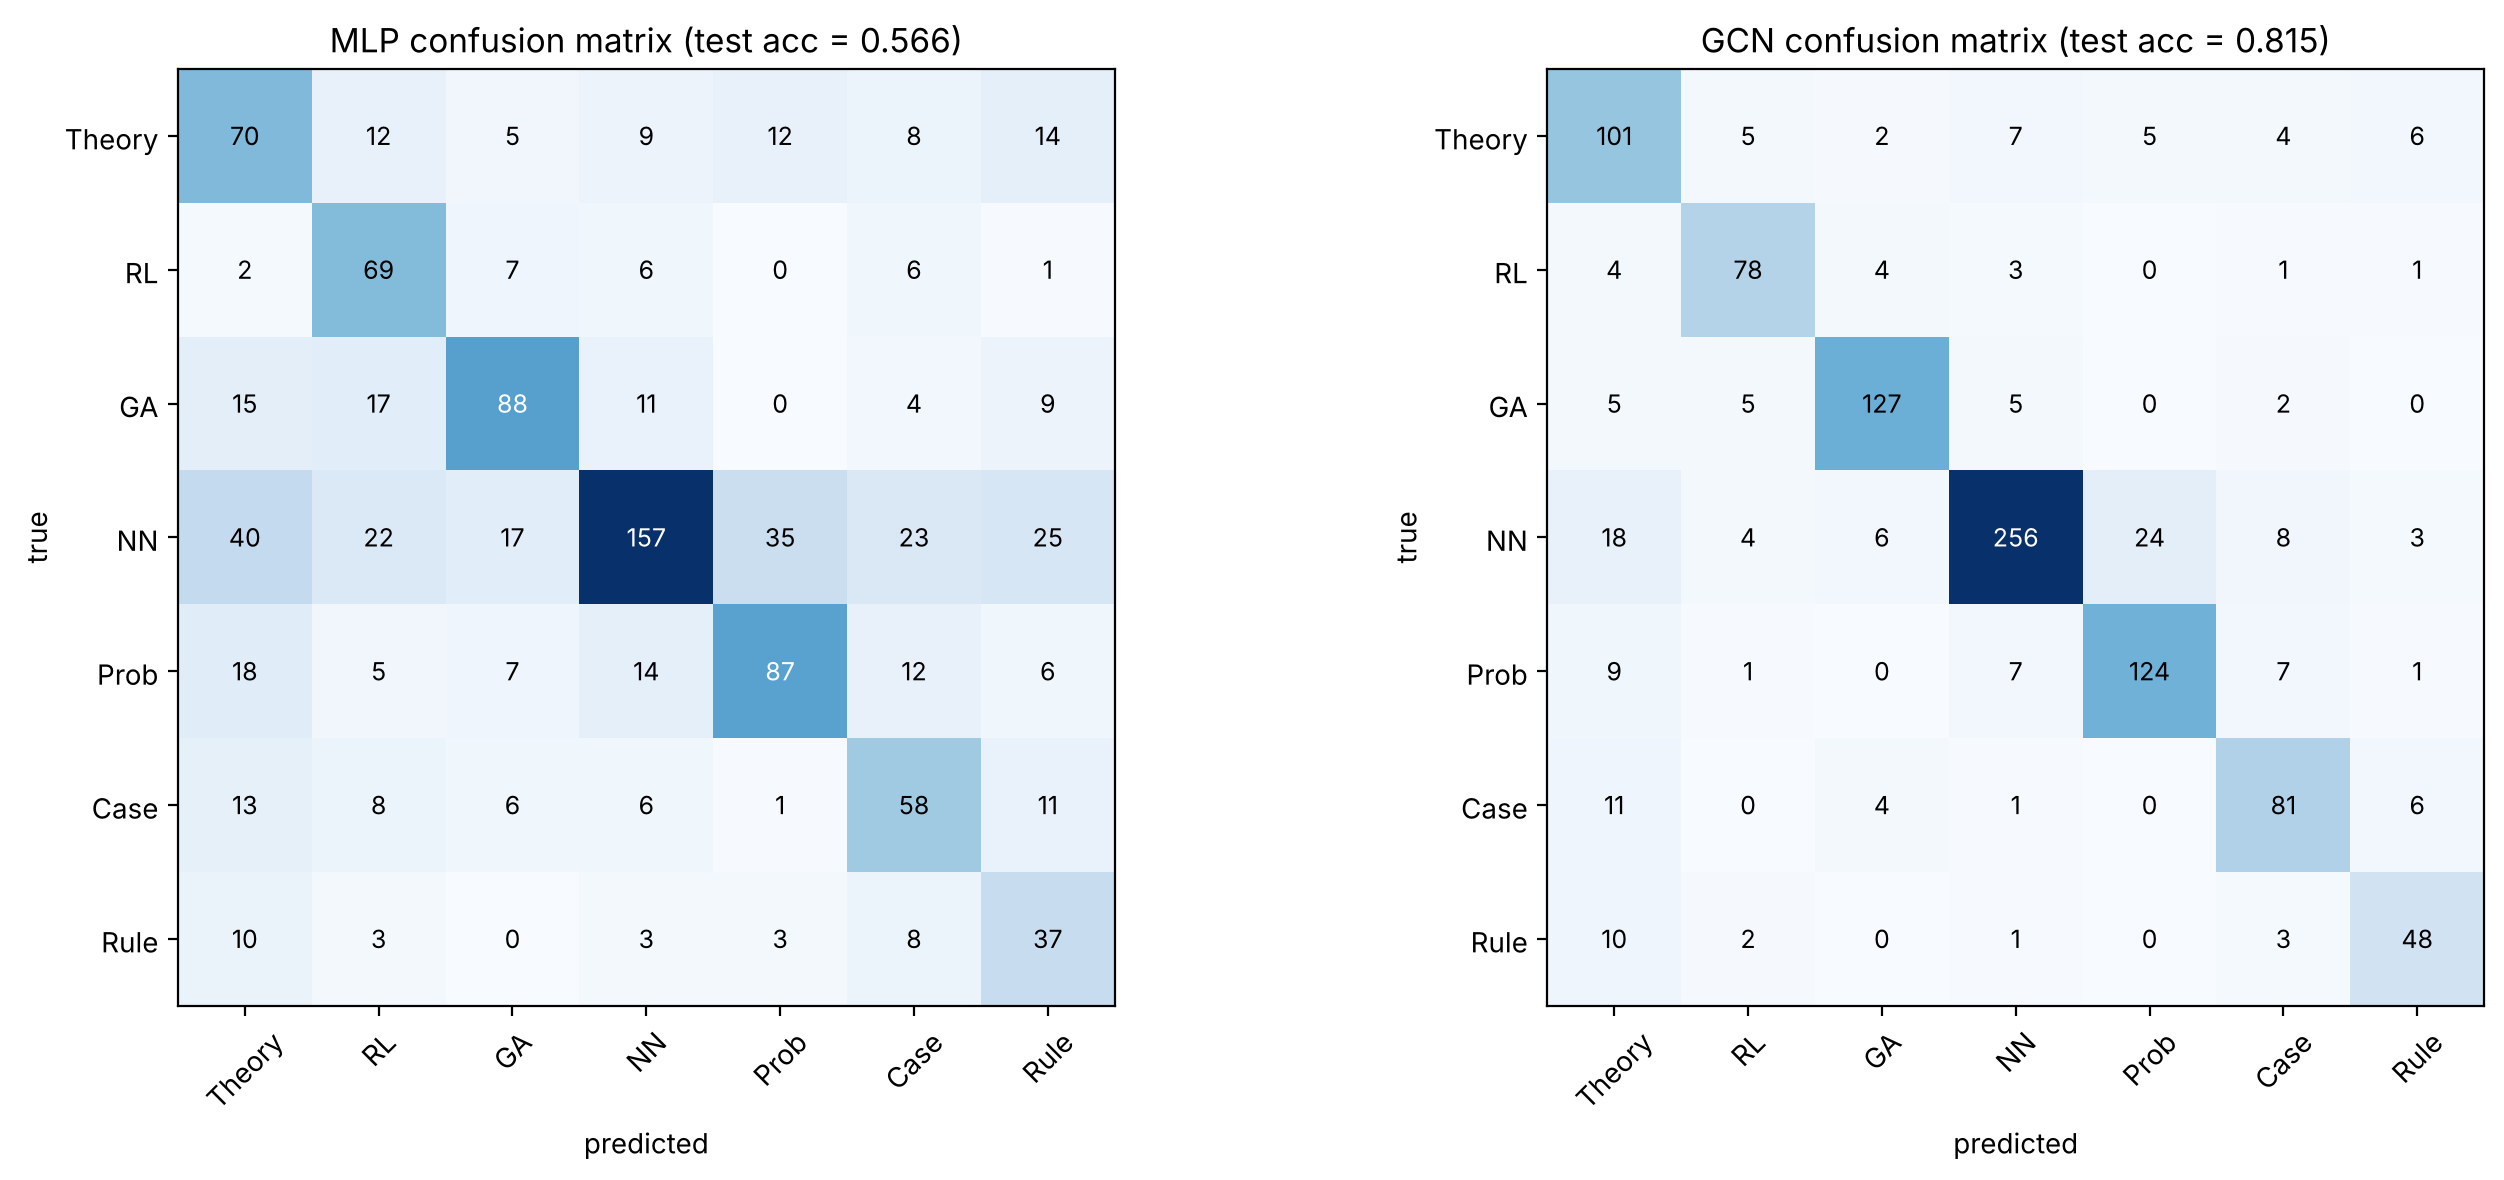


--- classification report: MLP ---
                        precision    recall  f1-score   support

                Theory      0.417     0.538     0.470       130
Reinforcement_Learning      0.507     0.758     0.608        91
    Genetic_Algorithms      0.677     0.611     0.642       144
       Neural_Networks      0.762     0.492     0.598       319
 Probabilistic_Methods      0.630     0.584     0.606       149
            Case_Based      0.487     0.563     0.523       103
         Rule_Learning      0.359     0.578     0.443        64

              accuracy                          0.566      1000
             macro avg      0.549     0.589     0.556      1000
          weighted avg      0.608     0.566     0.572      1000


--- classification report: GCN ---
                        precision    recall  f1-score   support

                Theory      0.639     0.777     0.701       130
Reinforcement_Learning      0.821     0.857     0.839        91
    Genetic_Algorithms      

In [11]:
# بخش ۹: ماتریس درهم‌ریختگی و گزارش طبقه‌بندی
y_test = data.y[data.test_mask].cpu().numpy()
mask_np = data.test_mask.cpu().numpy()
short = ["Theory", "RL", "GA", "NN", "Prob", "Case", "Rule"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, res) in zip(axes, [("MLP", res_mlp), ("GCN", res_gcn)]):
    cm = confusion_matrix(y_test, res["pred"][mask_np])
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(num_classes)); ax.set_xticklabels(short, rotation=45)
    ax.set_yticks(range(num_classes)); ax.set_yticklabels(short)
    for i in range(num_classes):
        for j in range(num_classes):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{name} confusion matrix (test acc = {res['test_acc']:.3f})")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "05_confusion_matrices.png"), dpi=150)
plt.show()

for name, res in [("MLP", res_mlp), ("GCN", res_gcn)]:
    print(f"\n--- classification report: {name} ---")
    print(classification_report(y_test, res["pred"][mask_np], target_names=CLASS_NAMES, digits=3))

## بخش ۱۰: نمایش دوبعدی بازنمایی لایه پنهان (t-SNE)

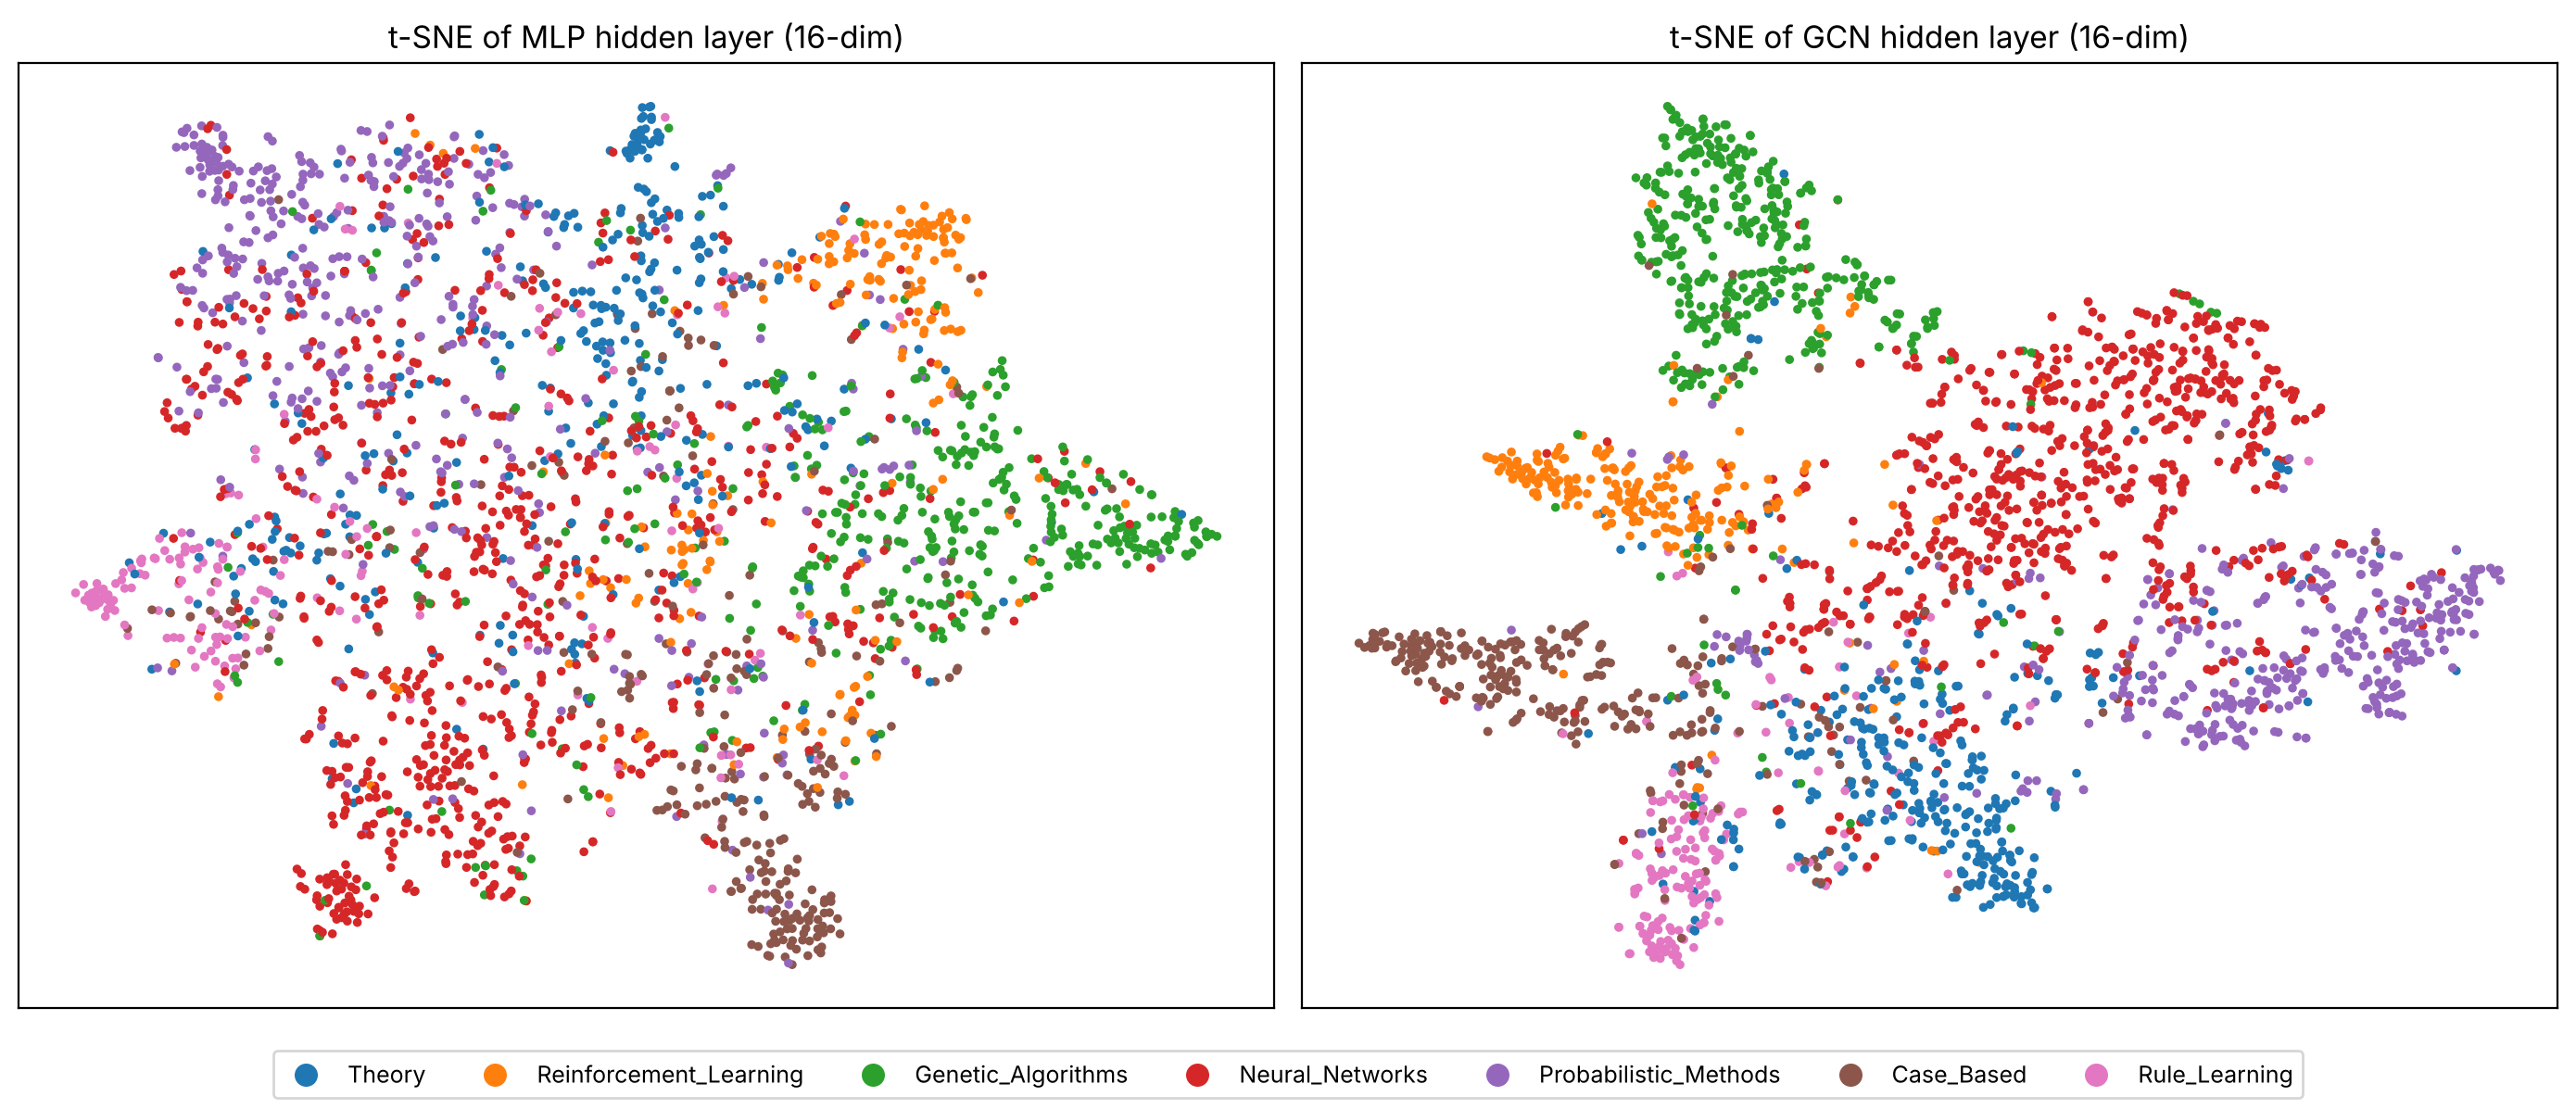

In [12]:
# بخش ۱۰: نمایش دوبعدی بازنمایی لایه پنهان (t-SNE)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, res) in zip(axes, [("MLP", res_mlp), ("GCN", res_gcn)]):
    emb2d = TSNE(n_components=2, random_state=SEED, init="pca").fit_transform(res["hidden"])
    ax.scatter(emb2d[:, 0], emb2d[:, 1], c=labels_np, cmap="tab10", vmin=0, vmax=9, s=6)
    ax.set_title(f"t-SNE of {name} hidden layer (16-dim)"); ax.set_xticks([]); ax.set_yticks([])
fig.legend(handles=handles, loc="lower center", ncol=7, fontsize=9)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig(os.path.join(FIG_DIR, "06_tsne_hidden.png"), dpi=150)
plt.show()

## بخش ۱۱: تکرار آزمایش با 10 seed مختلف برای اطمینان از نتیجه


========== Final comparison (10 seeds) ==========
MLP: test accuracy = 58.20 ± 0.76 %
GCN: test accuracy = 81.95 ± 0.84 %
بهبود دقت GCN نسبت به MLP: 23.75 درصد (واحد درصد)


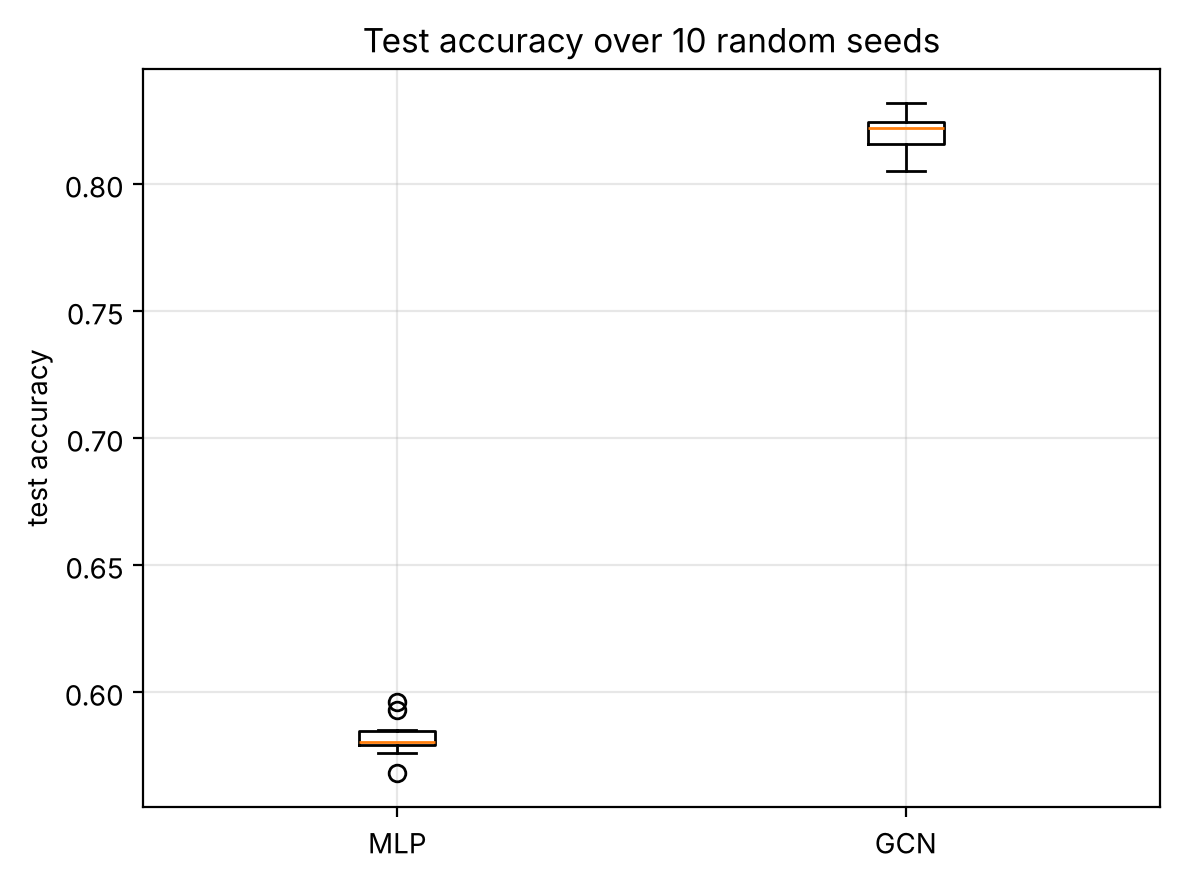


تمام نمودارها در پوشه outputs/figures و نتایج در outputs/results.json ذخیره شد.


In [13]:
# بخش ۱۱: تکرار آزمایش با 10 seed مختلف برای اطمینان از نتیجه
N_RUNS = 10
runs = {"MLP": [], "GCN": []}
for s in range(N_RUNS):
    for name, cls in [("MLP", MLP), ("GCN", GCN)]:
        set_seed(s)
        m = cls(num_features, HIDDEN, num_classes, DROPOUT).to(device)
        train_model(m, verbose=False)
        runs[name].append(evaluate(m)["test_acc"])

print("\n========== Final comparison (10 seeds) ==========")
summary = {}
for name in ["MLP", "GCN"]:
    arr = np.array(runs[name])
    summary[name] = {"mean": float(arr.mean()), "std": float(arr.std()), "runs": arr.tolist()}
    print(f"{name}: test accuracy = {arr.mean() * 100:.2f} ± {arr.std() * 100:.2f} %")
gain = (summary["GCN"]["mean"] - summary["MLP"]["mean"]) * 100
print(f"بهبود دقت GCN نسبت به MLP: {gain:.2f} درصد (واحد درصد)")

plt.figure(figsize=(6, 4.5))
plt.boxplot([runs["MLP"], runs["GCN"]], tick_labels=["MLP", "GCN"])
plt.ylabel("test accuracy"); plt.title(f"Test accuracy over {N_RUNS} random seeds")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "07_accuracy_boxplot.png"), dpi=150)
plt.show()

# ذخیره نتایج عددی
results = {
    "dataset": {"nodes": num_nodes, "edges": data.num_edges // 2, "features": num_features,
                "classes": num_classes, "train": int(data.train_mask.sum()),
                "val": int(data.val_mask.sum()), "test": int(data.test_mask.sum()),
                "homophily": homophily, "class_counts": class_counts.tolist()},
    "hyperparameters": {"hidden": HIDDEN, "dropout": DROPOUT, "lr": LR,
                        "weight_decay": WEIGHT_DECAY, "epochs": EPOCHS},
    "params": {"MLP": count_params(mlp), "GCN": count_params(gcn)},
    "seed42": {"MLP": {"test_acc": res_mlp["test_acc"], "macro_f1": res_mlp["test_macro_f1"],
                       "best_val_acc": max(hist_mlp["val_acc"]),
                       "final_train_acc": hist_mlp["train_acc"][-1]},
               "GCN": {"test_acc": res_gcn["test_acc"], "macro_f1": res_gcn["test_macro_f1"],
                       "best_val_acc": max(hist_gcn["val_acc"]),
                       "final_train_acc": hist_gcn["train_acc"][-1]}},
    "multi_seed": summary,
    "subgraph": {"nodes": G_sub.number_of_nodes(), "edges": G_sub.number_of_edges()},
}
with open(os.path.join(OUT_DIR, "results.json"), "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print("\nتمام نمودارها در پوشه outputs/figures و نتایج در outputs/results.json ذخیره شد.")